# Tuần 4 — Hoàn thiện Preprocessing & Kiểm tra Leakage

**Input:** `cic_ids_2017_cleaned.parquet` (kết quả tuần 3 — đã loại duplicate, không còn NaN/Inf)

**Nội dung:**
1. Rà soát lại cleaning (NaN, Infinity, duplicate, datatype)
2. Chia train / validation / test theo tỉ lệ **70 / 15 / 15**, **stratify theo nhãn**
3. Preprocessing — Encoder, Scaler, Feature Selection, **Undersampling**: chỉ `fit` trên **train**
4. Kiểm tra Leakage
5. Lưu kết quả để dùng cho bước huấn luyện

> **Xử lý mất cân bằng lớp:** chỉ dùng **Random Undersampling** (không dùng SMOTE vì mẫu sinh ra dễ vi phạm ràng buộc giữa các đặc trưng). Undersampling chỉ áp dụng cho tập **train**; validation và test giữ nguyên phân bố gốc.

### 0. Cài thư viện & tải dữ liệu

In [1]:
!pip install -q scikit-learn imbalanced-learn joblib

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np

CLEANED_PATH = "/content/drive/MyDrive/TTTN/tuan3_outputs/cic_ids_2017_cleaned.parquet"
df = pd.read_parquet(CLEANED_PATH)

print("Shape dữ liệu đầu vào:", df.shape)
print(df["Label_binary"].value_counts())

Shape dữ liệu đầu vào: (1739048, 85)
Label_binary
0    1457161
1     281887
Name: count, dtype: int64


## 1. Rà soát lại cleaning (NaN, Infinity, duplicate, datatype)

In [4]:
# 1.1. NaN / Inf / datatype
non_feature_cols = ["Label", "Label_binary", "__source_file"]
FEATURE_COLS = [c for c in df.columns if c not in non_feature_cols]
print("Số feature:", len(FEATURE_COLS))

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

n_nan = int(df[num_cols].isnull().sum().sum())
n_inf = int(np.isinf(df[num_cols]).sum().sum())
non_numeric_features = [c for c in FEATURE_COLS if c not in num_cols]

print(f"NaN còn lại: {n_nan}")
print(f"Inf còn lại: {n_inf}")
print("Feature không phải dạng số:", non_numeric_features if non_numeric_features else "Không có")

assert n_nan == 0 and n_inf == 0 and not non_numeric_features, "Dữ liệu chưa sạch -- quay lại bước cleaning tuần 3!"
print("\nOK -- không có NaN/Inf, mọi feature đều là số.")

Số feature: 82
NaN còn lại: 0
Inf còn lại: 0
Feature không phải dạng số: Không có

OK -- không có NaN/Inf, mọi feature đều là số.


**1.2. Duplicate theo feature (bổ sung so với tuần 3)**

Tuần 3 loại trùng lặp theo *feature + nhãn gốc*. Tuy nhiên với bài toán **nhị phân**, còn 2 loại dòng cần xử lý để không gây rò rỉ/nhiễu giữa train–val–test:

- **Trùng feature + cùng nhãn nhị phân** (chỉ khác tên tấn công chi tiết): giữ lại 1 dòng.
- **Trùng feature nhưng khác nhãn nhị phân** (ví dụ cùng một flow vừa là `Benign` vừa là `Infiltration - Portscan`): nhãn mâu thuẫn, không thể học đúng → **loại bỏ toàn bộ** các dòng này.

In [5]:
n0 = len(df)

# (a) trùng feature + cùng Label_binary -> giữ 1 dòng
df = df.drop_duplicates(subset=FEATURE_COLS + ["Label_binary"]).reset_index(drop=True)
n_same_label = n0 - len(df)

# (b) trùng feature nhưng khác Label_binary -> nhãn mâu thuẫn, loại hết
conflict_mask = df.duplicated(subset=FEATURE_COLS, keep=False)
print("Các nhãn nằm trong nhóm mâu thuẫn:")
print(df.loc[conflict_mask, "Label"].value_counts())
n_conflict = int(conflict_mask.sum())
df = df.loc[~conflict_mask].reset_index(drop=True)

print(f"\nTrùng feature + cùng nhãn nhị phân (đã giữ 1 dòng): loại {n_same_label:,} dòng")
print(f"Trùng feature nhưng khác nhãn nhị phân (mâu thuẫn): loại {n_conflict:,} dòng")
print(f"Số dòng: {n0:,} -> {len(df):,}")

# Sau bước này, không còn 2 dòng nào có feature giống hệt nhau
assert df.duplicated(subset=FEATURE_COLS).sum() == 0
print("OK -- không còn dòng trùng feature.")

Các nhãn nằm trong nhóm mâu thuẫn:
Label
Infiltration - Portscan    746
Benign                     746
Name: count, dtype: int64

Trùng feature + cùng nhãn nhị phân (đã giữ 1 dòng): loại 13 dòng
Trùng feature nhưng khác nhãn nhị phân (mâu thuẫn): loại 1,492 dòng
Số dòng: 1,739,048 -> 1,737,543
OK -- không còn dòng trùng feature.


In [6]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 250)

# 1) Đọc dữ liệu và tìm các dòng mâu thuẫn nhãn
df_raw = pd.read_parquet(CLEANED_PATH)
FEATURE_COLS = [c for c in df_raw.columns if c not in ["Label", "Label_binary", "__source_file"]]

d = df_raw.drop_duplicates(subset=FEATURE_COLS + ["Label_binary"]).reset_index(drop=True)
del df_raw

conflict_mask = d.duplicated(subset=FEATURE_COLS, keep=False)
conflict_rows = d.loc[conflict_mask].copy()
conflict_rows["group_id"] = conflict_rows.groupby(FEATURE_COLS, sort=False).ngroup()

# Đưa group_id và các cột nhãn lên đầu, sắp xếp để các dòng giống nhau nằm cạnh nhau
front = ["group_id", "Label", "Label_binary", "__source_file"]
conflict_sorted = (
    conflict_rows[front + FEATURE_COLS]
    .sort_values(["group_id", "Label_binary"])
    .reset_index(drop=True)
)

# 2) Xem trực tiếp N dòng đầu, đầy đủ đặc trưng
N = 20
display(conflict_sorted.head(N))

# 3) Xem 1 nhóm cụ thể dạng bảng dọc (mỗi cột là 1 dòng, mỗi hàng là 1 đặc trưng)
gid = conflict_sorted["group_id"].iloc[0]   # đổi sang group_id khác nếu muốn
display(conflict_sorted[conflict_sorted["group_id"] == gid].T)

,group_id,Label,Label_binary,__source_file,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd RST Flags,Bwd RST Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,ICMP Code,ICMP Type,Total TCP Flow Time
0,0,Benign,0,Infiltration-Webattacks-Thursday.parquet,6,47,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.255319e+04,47.0,0.0,47.0,47.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,24,20,21276.595703,21276.595703,0.0,0.0,0.0,0.0,0.0,0,1,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1024,0,0,24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,47
1,0,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,47,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.255319e+04,47.0,0.0,47.0,47.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,24,20,21276.595703,21276.595703,0.0,0.0,0.0,0.0,0.0,0,1,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1024,0,0,24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,47
2,1,Benign,0,Infiltration-Webattacks-Thursday.parquet,6,49,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.081633e+04,49.0,0.0,49.0,49.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,24,20,20408.164062,20408.164062,0.0,0.0,0.0,0.0,0.0,0,1,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1024,0,0,24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,49
3,1,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,49,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.081633e+04,49.0,0.0,49.0,49.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,24,20,20408.164062,20408.164062,0.0,0.0,0.0,0.0,0.0,0,1,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1024,0,0,24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,49
4,2,Benign,0,Infiltration-Webattacks-Thursday.parquet,6,48,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.166667e+04,48.0,0.0,48.0,48.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,24,20,20833.333984,20833.333984,0.0,0.0,0.0,0.0,0.0,0,1,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1024,0,0,24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,48
5,2,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,48,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.166667e+04,48.0,0.0,48.0,48.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,24,20,20833.333984,20833.333984,0.0,0.0,0.0,0.0,0.0,0,1,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1024,0,0,24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,48
6,3,Benign,0,Infiltration-Webattacks-Thursday.parquet,6,44,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.545455e+04,44.0,0.0,44.0,44.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,1,24,20,22727.273438,22727.273438,0.0,0.0,0.0,0.0,0.0,0,1,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1024,0,0,24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-1,-1,44
7,3,Infiltration - Portscan,1,Infiltration-Webattacks-Thursday.parquet,6,44,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.545455e+04,44.0,0.0

,0,1
group_id,0,0
Label,Benign,Infiltration - Portscan
Label_binary,0,1
__source_file,Infiltration-Webattacks-Thursday.parquet,Infiltration-Webattacks-Thursday.parquet
Protocol,6,6
Flow Duration,47,47
Total Fwd Packets,1,1
Total Backward Packets,1,1
Fwd Packets Length Total,0.0,0.0
Bwd Packets Length Total,0.0,0.0


## 2. Chia train / validation / test (70 / 15 / 15), stratify theo nhãn

- Bước 1: tách 70% train, 30% còn lại (temp)
- Bước 2: chia đôi temp thành 15% validation, 15% test

`stratify` đảm bảo tỉ lệ Benign/Attack giữ nguyên ở cả 3 tập. Việc chia tập được thực hiện **trước** mọi bước `fit` (scaler, feature selection, undersampling).

In [7]:
from sklearn.model_selection import train_test_split
import gc

# Giữ nguyên dtype gốc khi chia (KHÔNG ép float32 ở đây: sẽ làm mất độ chính xác các cột số lớn
# và khiến các dòng khác nhau bị coi là giống nhau). Chỉ ép float32 SAU khi scale.
X = df[FEATURE_COLS]
y = df["Label_binary"].astype("int8")

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

del X, X_temp, y_temp
gc.collect()

print("Train:", X_train.shape, "| tỉ lệ Attack:", round(y_train.mean(), 4))
print("Val:  ", X_val.shape,   "| tỉ lệ Attack:", round(y_val.mean(), 4))
print("Test: ", X_test.shape,  "| tỉ lệ Attack:", round(y_test.mean(), 4))

Train: (1216280, 82) | tỉ lệ Attack: 0.1618
Val:   (260631, 82) | tỉ lệ Attack: 0.1618
Test:  (260632, 82) | tỉ lệ Attack: 0.1618


In [8]:
# Lưu "dấu vân tay" (hash) của từng dòng TRƯỚC khi biến đổi -- dùng cho bước kiểm tra leakage ở mục 4
hash_train = set(pd.util.hash_pandas_object(X_train, index=False).values)
hash_val = set(pd.util.hash_pandas_object(X_val, index=False).values)
hash_test = set(pd.util.hash_pandas_object(X_test, index=False).values)

idx_train, idx_val, idx_test = set(X_train.index), set(X_val.index), set(X_test.index)
n_train_before_resample = len(X_train)
n_val_before, n_test_before = len(X_val), len(X_test)
print("Đã lưu hash/index của 3 tập để kiểm tra leakage.")

Đã lưu hash/index của 3 tập để kiểm tra leakage.


## 3. Preprocessing — chỉ `fit` trên train

Nguyên tắc: mọi bước có tham số học từ dữ liệu (scaler, feature selection, undersampling) chỉ được `fit` trên tập **train**.
Validation và test chỉ được `transform` bằng tham số đã học từ train.

### 3.1. Encoder

In [9]:
# Toàn bộ feature CICFlowMeter đều là số (đã kiểm tra ở mục 1) -> không có cột categorical cần encode.
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
print("Cột categorical trong feature:", cat_cols if cat_cols else "Không có -- bỏ qua bước encoding.")

Cột categorical trong feature: Không có -- bỏ qua bước encoding.


### 3.2. Scaler (StandardScaler) — fit trên train

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(X_train)  # CHỈ fit trên train

X_train_s = pd.DataFrame(scaler.transform(X_train).astype("float32"), columns=FEATURE_COLS, index=X_train.index)
X_val_s = pd.DataFrame(scaler.transform(X_val).astype("float32"), columns=FEATURE_COLS, index=X_val.index)
X_test_s = pd.DataFrame(scaler.transform(X_test).astype("float32"), columns=FEATURE_COLS, index=X_test.index)

del X_train, X_val, X_test
gc.collect()

print("Mean lớn nhất sau scale (train, phải ~0):", float(X_train_s.mean().abs().max()))
print("Std trung bình sau scale (train, phải ~1):", float(X_train_s.std().mean()))

Mean lớn nhất sau scale (train, phải ~0): 3.0510552306850514e-08
Std trung bình sau scale (train, phải ~1): 0.9989426732063293


### 3.3. Feature Selection (VarianceThreshold) — fit trên train

In [11]:
from sklearn.feature_selection import VarianceThreshold

# Loại các feature có phương sai gần 0 (hằng số / gần hằng số) -- phương sai tính CHỈ trên train
selector = VarianceThreshold(threshold=0.01)
selector.fit(X_train_s)

mask = selector.get_support()
SELECTED_FEATURES = [c for c, keep in zip(FEATURE_COLS, mask) if keep]
DROPPED_FEATURES = [c for c, keep in zip(FEATURE_COLS, mask) if not keep]

print(f"Số feature giữ lại: {len(SELECTED_FEATURES)} / {len(FEATURE_COLS)}")
print(f"Số feature bị loại: {len(DROPPED_FEATURES)}")
if DROPPED_FEATURES:
    print("Feature bị loại:", DROPPED_FEATURES)

X_train_f = X_train_s[SELECTED_FEATURES]
X_val_f = X_val_s[SELECTED_FEATURES]
X_test_f = X_test_s[SELECTED_FEATURES]

del X_train_s, X_val_s, X_test_s
gc.collect()

Số feature giữ lại: 82 / 82
Số feature bị loại: 0


0

### 3.4. Class weight (balanced) — tính trên train

Không loại hay thêm dòng nào. Mỗi lớp được gán trọng số `n_samples / (n_classes * n_lớp)`, tính **chỉ trên `y_train`**. Lớp Attack (ít hơn) có trọng số lớn hơn Benign.

In [12]:
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight

classes = np.array([0, 1])

# Trọng số CHỈ tính từ y_train (không dùng val/test)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
CLASS_WEIGHT = {int(c): float(w) for c, w in zip(classes, weights)}

n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
SCALE_POS_WEIGHT = n_neg / n_pos   # dùng cho XGBoost / LightGBM

print("Phân bố nhãn train (giữ nguyên, không loại/thêm dòng):")
print(y_train.value_counts())
print("\nTrọng số lớp (balanced):", {k: round(v, 4) for k, v in CLASS_WEIGHT.items()})
print("scale_pos_weight (XGBoost/LightGBM):", round(SCALE_POS_WEIGHT, 4))

Phân bố nhãn train (giữ nguyên, không loại/thêm dòng):
Label_binary
0    1019490
1     196790
Name: count, dtype: int64

Trọng số lớp (balanced): {0: 0.5965, 1: 3.0903}
scale_pos_weight (XGBoost/LightGBM): 5.1806


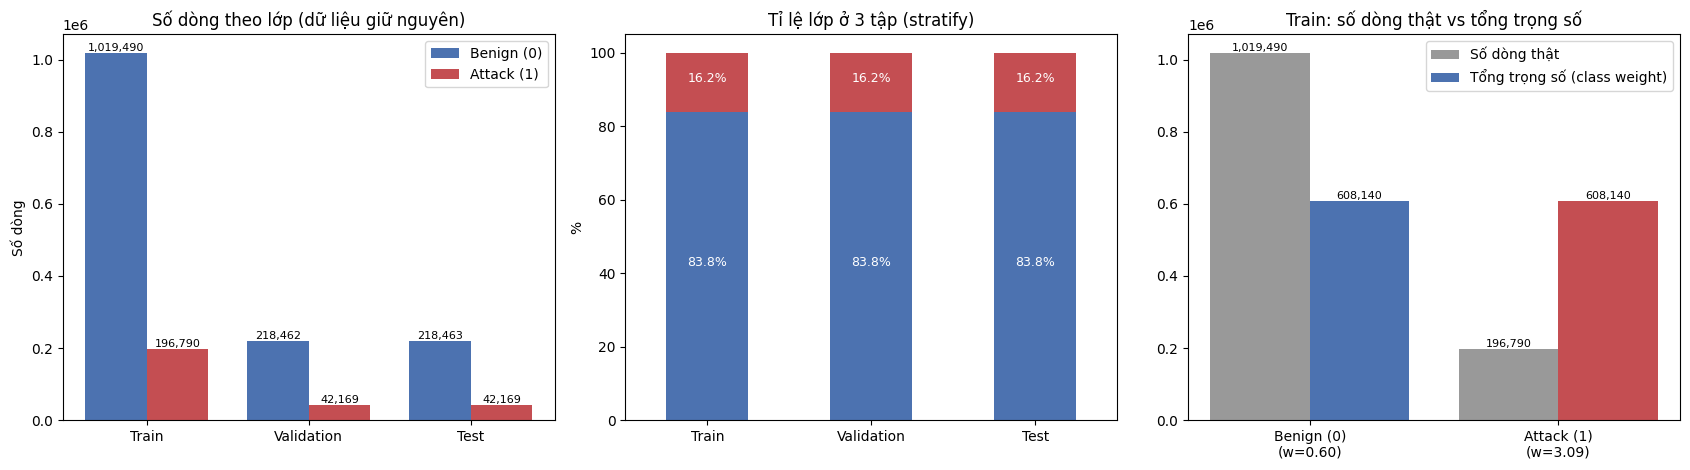

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

names = ["Benign (0)", "Attack (1)"]
colors = ["#4C72B0", "#C44E52"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# (1) Số dòng mỗi lớp ở train / val / test -- dữ liệu KHÔNG đổi sau class weight
sets = {"Train": y_train, "Validation": y_val, "Test": y_test}
x = np.arange(len(sets))
width = 0.38
for j, cls in enumerate([0, 1]):
    vals = [int((s == cls).sum()) for s in sets.values()]
    bars = axes[0].bar(x + (j - 0.5) * width, vals, width, label=names[j], color=colors[j])
    for b, v in zip(bars, vals):
        axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(sets.keys())
axes[0].set_title("Số dòng theo lớp (dữ liệu giữ nguyên)")
axes[0].set_ylabel("Số dòng")
axes[0].legend()

# (2) Tỉ lệ % mỗi lớp ở 3 tập -- bằng nhau nhờ stratify
pct = pd.DataFrame({k: s.value_counts(normalize=True).sort_index() * 100 for k, s in sets.items()}).T
pct.columns = names
pct.plot(kind="bar", stacked=True, ax=axes[1], color=colors, rot=0, legend=False)
for i, (_, row) in enumerate(pct.iterrows()):
    axes[1].text(i, row.iloc[0] / 2, f"{row.iloc[0]:.1f}%", ha="center", color="white", fontsize=9)
    axes[1].text(i, row.iloc[0] + row.iloc[1] / 2, f"{row.iloc[1]:.1f}%", ha="center", color="white", fontsize=9)
axes[1].set_title("Tỉ lệ lớp ở 3 tập (stratify)")
axes[1].set_ylabel("%")

# (3) Tập train: số dòng thật vs tổng trọng số (mức mô hình "nhìn thấy" khi huấn luyện)
counts = np.array([(y_train == 0).sum(), (y_train == 1).sum()], dtype=float)
weighted = counts * np.array([CLASS_WEIGHT[0], CLASS_WEIGHT[1]])
x2 = np.arange(2)
b1 = axes[2].bar(x2 - 0.2, counts, 0.4, label="Số dòng thật", color="#999999")
b2 = axes[2].bar(x2 + 0.2, weighted, 0.4, label="Tổng trọng số (class weight)", color=colors)
for bars, vals in [(b1, counts), (b2, weighted)]:
    for b, v in zip(bars, vals):
        axes[2].text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=8)
axes[2].set_xticks(x2)
axes[2].set_xticklabels([f"{n}\n(w={CLASS_WEIGHT[i]:.2f})" for i, n in enumerate(names)])
axes[2].set_title("Train: số dòng thật vs tổng trọng số")
axes[2].legend()

plt.tight_layout()
plt.show()

## 4. Kiểm tra Leakage

Các kiểm tra dưới đây nên được chạy và đối chiếu cùng các thành viên khác trong nhóm.

In [14]:
# 4.1. Không có dòng nào (theo chỉ mục) nằm ở 2 tập khác nhau
print("Giao index train & val :", len(idx_train & idx_val), "(phải = 0)")
print("Giao index train & test:", len(idx_train & idx_test), "(phải = 0)")
print("Giao index val & test  :", len(idx_val & idx_test), "(phải = 0)")

assert len(idx_train & idx_val) == 0 and len(idx_train & idx_test) == 0 and len(idx_val & idx_test) == 0

Giao index train & val : 0 (phải = 0)
Giao index train & test: 0 (phải = 0)
Giao index val & test  : 0 (phải = 0)


In [15]:
# 4.2. Không có dòng trùng NỘI DUNG giữa các tập (so sánh bằng hash của feature gốc, trước khi scale)
print("Dòng trùng nội dung train & val :", len(hash_train & hash_val), "(phải = 0)")
print("Dòng trùng nội dung train & test:", len(hash_train & hash_test), "(phải = 0)")
print("Dòng trùng nội dung val & test  :", len(hash_val & hash_test), "(phải = 0)")

assert len(hash_train & hash_val) == 0 and len(hash_train & hash_test) == 0 and len(hash_val & hash_test) == 0

Dòng trùng nội dung train & val : 0 (phải = 0)
Dòng trùng nội dung train & test: 0 (phải = 0)
Dòng trùng nội dung val & test  : 0 (phải = 0)


In [16]:
# 4.3. Scaler chỉ học từ train
print("Số mẫu scaler đã fit:", scaler.n_samples_seen_, "| Số dòng train:", n_train_before_resample)
assert scaler.n_samples_seen_ == n_train_before_resample, "Scaler bị fit sai tập dữ liệu!"

# 4.4. Feature selection chỉ học từ train: tính lại phương sai bằng float64 trên tập train rồi so với selector
keep = selector.get_support()
var_sel = selector.variances_[keep]
var_ref = X_train_f.to_numpy(dtype="float64").var(axis=0)
rel = np.abs(var_sel - var_ref) / np.maximum(np.abs(var_ref), 1e-12)

print("Số feature kiểm tra:", len(var_ref))
print("Lệch tương đối lớn nhất:", float(rel.max()))
for i in np.argsort(rel)[-3:][::-1]:
    print("  ", SELECTED_FEATURES[i], "| selector:", float(var_sel[i]), "| tính lại:", float(var_ref[i]))
print("Phương sai (train) của feature giữ lại nằm trong:", float(var_ref.min()), "->", float(var_ref.max()))
assert rel.max() < 1e-6, "Feature selector không được fit trên tập train!"
assert (var_ref > 0.01).all(), "Có feature được giữ lại nhưng phương sai trên train <= 0.01"

Số mẫu scaler đã fit: 1216280 | Số dòng train: 1216280
Số feature kiểm tra: 82
Lệch tương đối lớn nhất: 0.0
   Total TCP Flow Time | selector: 0.9999999976860584 | tính lại: 0.9999999976860584
   ICMP Type | selector: 0.9999999946798164 | tính lại: 0.9999999946798164
   ICMP Code | selector: 1.0000000191085323 | tính lại: 1.0000000191085323
Phương sai (train) của feature giữ lại nằm trong: 0.9999998983798967 -> 1.0000000599775418


In [17]:
# 4.5. Val/test không bị thay đổi số dòng
print(f"Val : {n_val_before:,} dòng trước -> {len(X_val_f):,} dòng sau (phải bằng nhau)")
print(f"Test: {n_test_before:,} dòng trước -> {len(X_test_f):,} dòng sau (phải bằng nhau)")
assert len(X_val_f) == n_val_before and len(X_test_f) == n_test_before

# 4.6. Class weight không đổi dữ liệu: train giữ nguyên số dòng, trọng số tính từ train
print(f"Train: {n_train_before_resample:,} dòng trước -> {len(X_train_f):,} dòng sau (phải bằng nhau)")
assert len(X_train_f) == n_train_before_resample

expected = {c: n_train_before_resample / (2 * int((y_train == c).sum())) for c in (0, 1)}
print("Trọng số kỳ vọng n/(2*n_c):", {k: round(v, 4) for k, v in expected.items()})
assert all(abs(CLASS_WEIGHT[c] - expected[c]) < 1e-9 for c in (0, 1)), "Trọng số không khớp công thức balanced!"

Val : 260,631 dòng trước -> 260,631 dòng sau (phải bằng nhau)
Test: 260,632 dòng trước -> 260,632 dòng sau (phải bằng nhau)
Train: 1,216,280 dòng trước -> 1,216,280 dòng sau (phải bằng nhau)
Trọng số kỳ vọng n/(2*n_c): {0: 0.5965, 1: 3.0903}


In [18]:
# 4.7. Tỉ lệ nhãn: train/val/test cùng tỉ lệ (stratify)
ratio = pd.DataFrame({
    "So_dong": [n_train_before_resample, len(X_val_f), len(X_test_f)],
    "Ti_le_Attack_%": [
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2),
        round(y_test.mean() * 100, 2),
    ],
}, index=["Train", "Validation", "Test"])
ratio

,So_dong,Ti_le_Attack_%
Train,1216280,16.18
Validation,260631,16.18
Test,260632,16.18


In [19]:
# 4.8. Không còn NaN/Inf sau toàn bộ biến đổi
for name, arr in [("X_train_f", X_train_f), ("X_val_f", X_val_f), ("X_test_f", X_test_f)]:
    v = arr.values
    print(f"{name}: NaN={int(np.isnan(v).sum())}, Inf={int(np.isinf(v).sum())}")

X_train_f: NaN=0, Inf=0
X_val_f: NaN=0, Inf=0
X_test_f: NaN=0, Inf=0


## 5. Lưu kết quả cho bước huấn luyện

In [20]:
import os, json, joblib

OUT_DIR = "/content/drive/MyDrive/TTTN/tuan4_outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Thư mục split_70_15_15 chứa 3 file parquet ----
SPLIT_DIR = f"{OUT_DIR}/split_70_15_15"
os.makedirs(SPLIT_DIR, exist_ok=True)

for s_name, Xf, y in [("train", X_train_f, y_train),
                      ("val",   X_val_f,   y_val),
                      ("test",  X_test_f,  y_test)]:
    part = Xf.copy()                                   # feature đã scale + đã chọn (float32)
    part.insert(0, "row_id", part.index.astype("int64"))   # chỉ mục gốc trong df, để truy ngược
    part["Label_binary"] = y.loc[Xf.index].to_numpy()      # nhãn nhị phân
    part = part.sort_values("row_id").reset_index(drop=True)
    part.to_parquet(f"{SPLIT_DIR}/{s_name}.parquet", index=False)
    print(f"Đã lưu {s_name}.parquet: {part.shape}")
    del part

# ---- Các file phụ giữ nguyên như cũ ----
joblib.dump(scaler, f"{OUT_DIR}/scaler.joblib")
joblib.dump(selector, f"{OUT_DIR}/feature_selector.joblib")

with open(f"{OUT_DIR}/selected_features.json", "w", encoding="utf-8") as f:
    json.dump({"selected": SELECTED_FEATURES, "dropped": DROPPED_FEATURES}, f, ensure_ascii=False, indent=2)

with open(f"{OUT_DIR}/class_weight.json", "w", encoding="utf-8") as f:
    json.dump({"class_weight": CLASS_WEIGHT, "scale_pos_weight": SCALE_POS_WEIGHT}, f, indent=2)

print("Đã lưu tại:", OUT_DIR)
print(os.listdir(OUT_DIR))
print(os.listdir(SPLIT_DIR))

Đã lưu train.parquet: (1216280, 84)
Đã lưu val.parquet: (260631, 84)
Đã lưu test.parquet: (260632, 84)
Đã lưu tại: /content/drive/MyDrive/TTTN/tuan4_outputs
['cic_ids_2017_cleaned.parquet', 'split_70_15_15', 'scaler.joblib', 'feature_selector.joblib', 'selected_features.json', 'class_weight.json']
['train.parquet', 'val.parquet', 'test.parquet']
